# EDA

In [134]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import aeronavx

# Users

In [135]:
users = pd.read_csv("../data/users.csv")

In [136]:
users

,user_id,birthdate,gender,married,has_children,home_country,home_city,home_airport,home_airport_lat,home_airport_lon,sign_up_date
0,94883,1972-03-16,F,True,False,usa,kansas city,MCI,39.297,-94.714,2022-02-07
1,101486,1972-12-07,F,True,True,usa,tacoma,TCM,47.138,-122.476,2022-02-17
2,101961,1980-09-14,F,True,False,usa,boston,BOS,42.364,-71.005,2022-02-17
3,106907,1978-11-17,F,True,True,usa,miami,TNT,25.862,-80.897,2022-02-24
4,118043,1972-05-04,F,False,True,usa,los angeles,LAX,33.942,-118.408,2022-03-10
...,...,...,...,...,...,...,...,...,...,...,...
5993,780167,1974-06-08,F,True,True,usa,los angeles,LAX,33.942,-118.408,2023-04-25
5994,785186,1979-06-03,F,True,True,usa,little rock,LIT,34.729,-92.224,2023-04-27
5995,792549,1978-01-25,F,False,False,usa,kansas city,MCI,39.297,-94.714,2023-04-30
5996,811077,1979-02-22,F,True,True,usa,knoxville,TYS,35.812,-83.993,2023-05-06


In [137]:
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 5998 entries, 0 to 5997
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5998 non-null   int64  
 1   birthdate         5998 non-null   str    
 2   gender            5998 non-null   str    
 3   married           5998 non-null   bool   
 4   has_children      5998 non-null   bool   
 5   home_country      5998 non-null   str    
 6   home_city         5998 non-null   str    
 7   home_airport      5998 non-null   str    
 8   home_airport_lat  5998 non-null   float64
 9   home_airport_lon  5998 non-null   float64
 10  sign_up_date      5998 non-null   str    
dtypes: bool(2), float64(2), int64(1), str(6)
memory usage: 433.6 KB


No nan values

In [138]:
users.describe()

,user_id,home_airport_lat,home_airport_lon
count,5998.000000,5998.000000,5998.000000
mean,545440.695565,38.439744,-94.176286
std,64924.749760,6.189297,18.071233
min,23557.000000,21.316000,-157.927000
25%,517152.000000,33.818000,-112.383000
50%,540542.000000,39.103000,-90.035000
75%,574146.000000,42.266500,-79.370000
max,844489.000000,61.251000,-63.499000


In [139]:
pd.to_datetime(users["birthdate"], format='%Y-%m-%d', errors='coerce').isnull().sum()

np.int64(0)

In [140]:
pd.to_datetime(users["sign_up_date"], format='%Y-%m-%d', errors='coerce').isnull().sum()

np.int64(0)

all dates are in the correct format

## Age Analysis

In [141]:
users["birthdate"] = pd.to_datetime(users["birthdate"])

In [142]:
# 2. Today's date
today = pd.Timestamp.now()   # or pd.Timestamp.today()

# 3. Compute age
users["age"] = (today - users["birthdate"]).dt.days // 365

In [143]:
users

,user_id,birthdate,gender,married,has_children,home_country,home_city,home_airport,home_airport_lat,home_airport_lon,sign_up_date,age
0,94883,1972-03-16,F,True,False,usa,kansas city,MCI,39.297,-94.714,2022-02-07,54
1,101486,1972-12-07,F,True,True,usa,tacoma,TCM,47.138,-122.476,2022-02-17,53
2,101961,1980-09-14,F,True,False,usa,boston,BOS,42.364,-71.005,2022-02-17,46
3,106907,1978-11-17,F,True,True,usa,miami,TNT,25.862,-80.897,2022-02-24,47
4,118043,1972-05-04,F,False,True,usa,los angeles,LAX,33.942,-118.408,2022-03-10,54
...,...,...,...,...,...,...,...,...,...,...,...,...
5993,780167,1974-06-08,F,True,True,usa,los angeles,LAX,33.942,-118.408,2023-04-25,52
5994,785186,1979-06-03,F,True,True,usa,little rock,LIT,34.729,-92.224,2023-04-27,47
5995,792549,1978-01-25,F,False,False,usa,kansas city,MCI,39.297,-94.714,2023-04-30,48
5996,811077,1979-02-22,F,True,True,usa,knoxville,TYS,35.812,-83.993,2023-05-06,47


<Axes: xlabel='age', ylabel='count'>

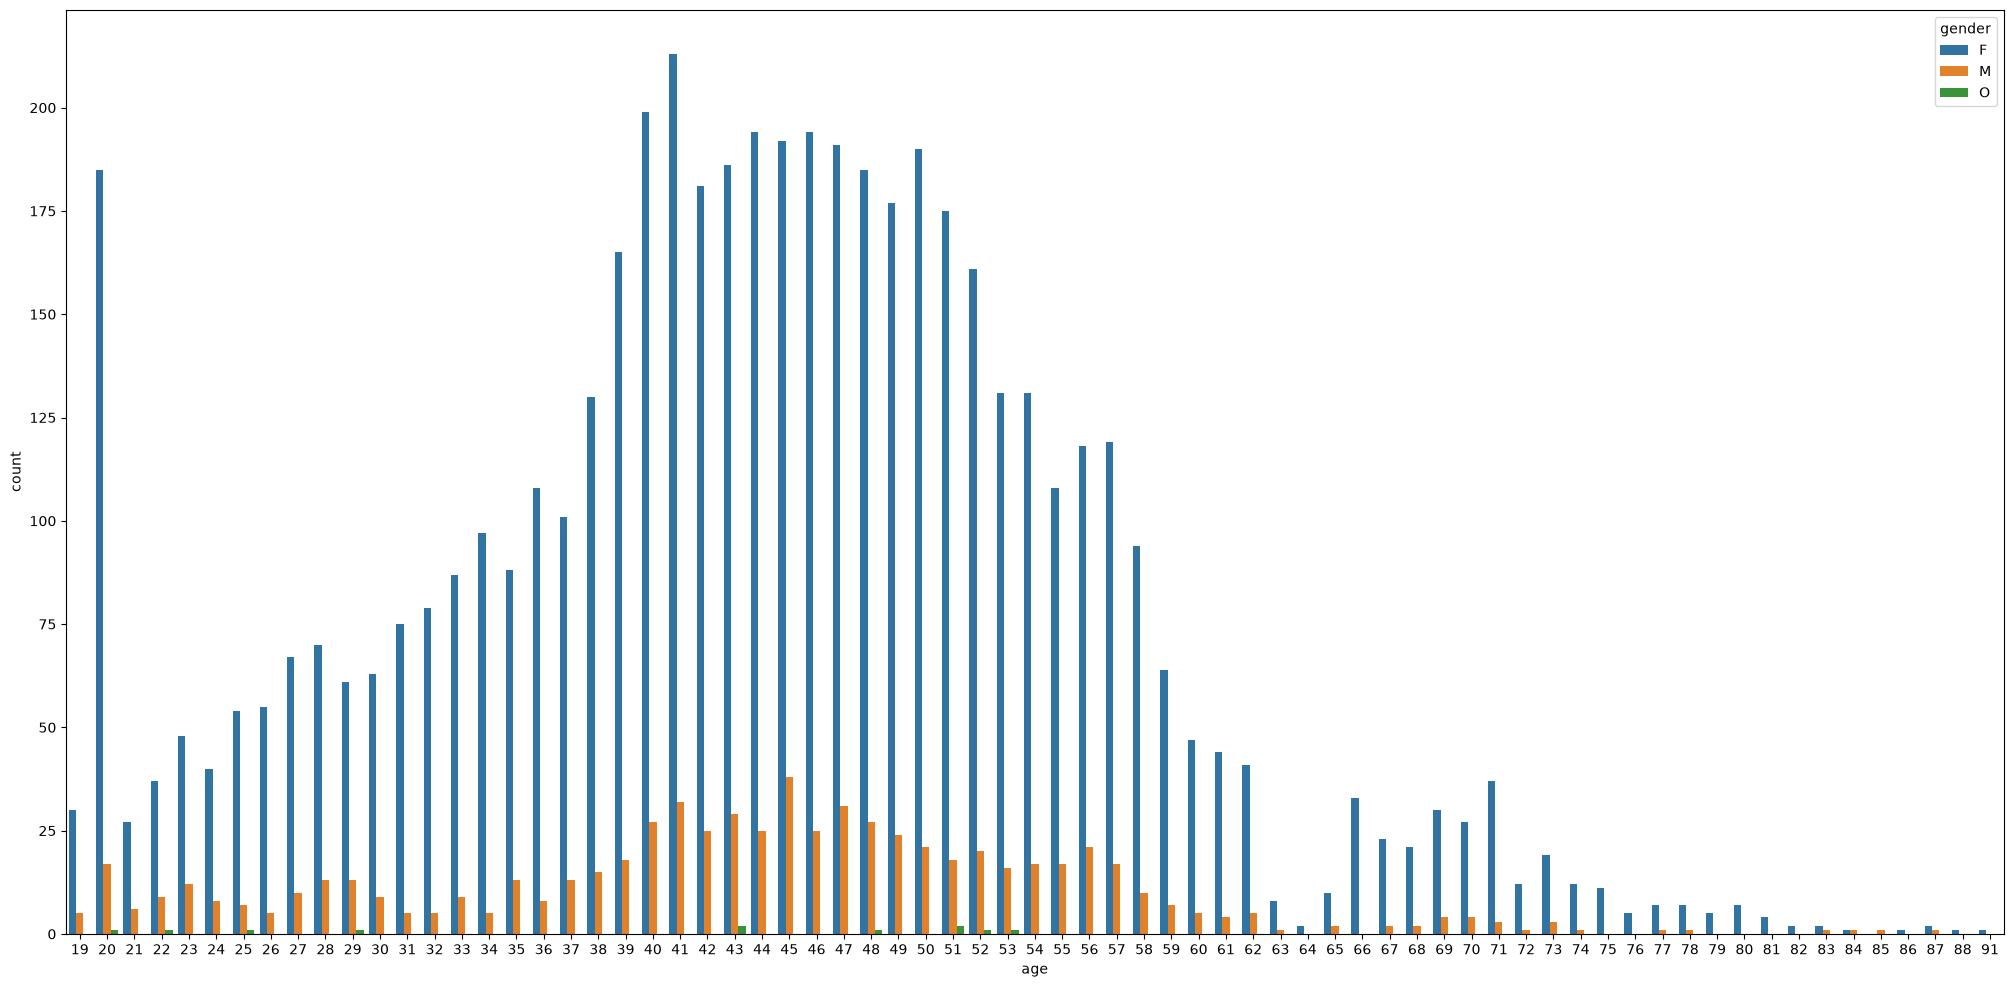

In [144]:
plt.figure(figsize=(25, 12))  # width, height in inches
sns.countplot(users,x = "age", hue="gender")

Interesting: at first look 3 groups, working, renter, youngs.

## Gender Analysis

In [145]:
users

,user_id,birthdate,gender,married,has_children,home_country,home_city,home_airport,home_airport_lat,home_airport_lon,sign_up_date,age
0,94883,1972-03-16,F,True,False,usa,kansas city,MCI,39.297,-94.714,2022-02-07,54
1,101486,1972-12-07,F,True,True,usa,tacoma,TCM,47.138,-122.476,2022-02-17,53
2,101961,1980-09-14,F,True,False,usa,boston,BOS,42.364,-71.005,2022-02-17,46
3,106907,1978-11-17,F,True,True,usa,miami,TNT,25.862,-80.897,2022-02-24,47
4,118043,1972-05-04,F,False,True,usa,los angeles,LAX,33.942,-118.408,2022-03-10,54
...,...,...,...,...,...,...,...,...,...,...,...,...
5993,780167,1974-06-08,F,True,True,usa,los angeles,LAX,33.942,-118.408,2023-04-25,52
5994,785186,1979-06-03,F,True,True,usa,little rock,LIT,34.729,-92.224,2023-04-27,47
5995,792549,1978-01-25,F,False,False,usa,kansas city,MCI,39.297,-94.714,2023-04-30,48
5996,811077,1979-02-22,F,True,True,usa,knoxville,TYS,35.812,-83.993,2023-05-06,47


<Axes: xlabel='gender'>

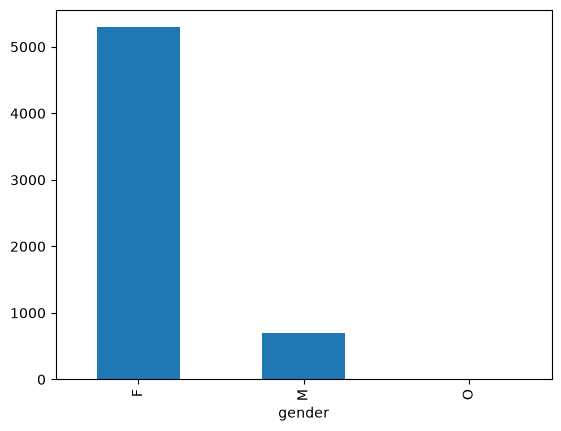

In [146]:
users["gender"].value_counts().plot(kind = "bar")

<Axes: >

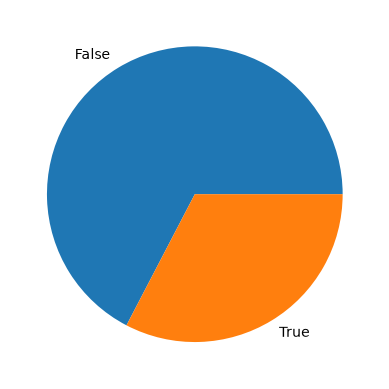

In [147]:
users["has_children"].value_counts().plot(kind = "pie")

<Axes: >

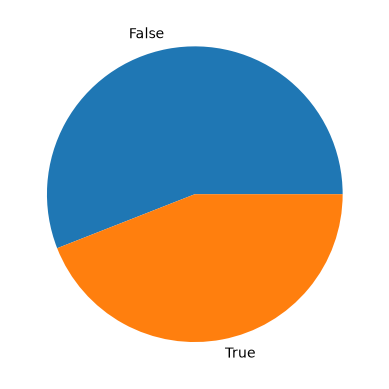

In [148]:
users["married"].value_counts().plot(kind = "pie")

In [149]:
users["home_country"].value_counts()

home_country
usa       4991
canada    1007
Name: count, dtype: int64

In [150]:
import plotly.express as px
import pandas as pd



# Create scatter map
fig = px.scatter_geo(
    users,
    lat='home_airport_lat',
    lon='home_airport_lon',
    color= 'age',
    width=1200,      # px
    height=800       # p
)

fig.show()
# fig.write_html("worldmap.html")

In [151]:
users

,user_id,birthdate,gender,married,has_children,home_country,home_city,home_airport,home_airport_lat,home_airport_lon,sign_up_date,age
0,94883,1972-03-16,F,True,False,usa,kansas city,MCI,39.297,-94.714,2022-02-07,54
1,101486,1972-12-07,F,True,True,usa,tacoma,TCM,47.138,-122.476,2022-02-17,53
2,101961,1980-09-14,F,True,False,usa,boston,BOS,42.364,-71.005,2022-02-17,46
3,106907,1978-11-17,F,True,True,usa,miami,TNT,25.862,-80.897,2022-02-24,47
4,118043,1972-05-04,F,False,True,usa,los angeles,LAX,33.942,-118.408,2022-03-10,54
...,...,...,...,...,...,...,...,...,...,...,...,...
5993,780167,1974-06-08,F,True,True,usa,los angeles,LAX,33.942,-118.408,2023-04-25,52
5994,785186,1979-06-03,F,True,True,usa,little rock,LIT,34.729,-92.224,2023-04-27,47
5995,792549,1978-01-25,F,False,False,usa,kansas city,MCI,39.297,-94.714,2023-04-30,48
5996,811077,1979-02-22,F,True,True,usa,knoxville,TYS,35.812,-83.993,2023-05-06,47


Idee: tenure verteilung

In [152]:
users.to_csv("../data_preprocessed/users_preprocessed.csv", index=False)

# Flights

In [153]:
flights = pd.read_csv("../data/flights.csv")

In [154]:
flights

,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd
0,204943-07ddf3a4d2a34e03befdbd07c78d9aab,YOW,new york,LGA,3,True,2023-03-06 07:00:00,2023-03-09 07:00:00,0,KLM Royal Dutch Airlines,40.640,-73.779,267.58
1,229330-b73ffe29221b40a086cd0107f85eac2b,COS,san antonio,RND,1,True,2023-02-26 15:00:00,2023-03-02 15:00:00,0,United Airlines,29.529,-98.279,213.01
2,283325-dd763c2d6d334b3790266b500393438e,DAL,quebec,YQB,1,True,2023-03-05 14:00:00,2023-03-11 14:00:00,0,Air Canada,46.788,-71.398,453.27
3,347778-1bc6f3542683460480d91602d0a05a22,LSV,san diego,NZY,1,True,2023-06-26 11:00:00,2023-06-29 11:00:00,1,Ryanair,32.699,-117.215,77.49
4,389434-cf10e38f0d464b81ace3f3be9f689833,LGA,hamilton,YHM,1,True,2023-04-06 07:00:00,2023-04-07 07:00:00,1,WestJet,43.173,-79.935,105.77
...,...,...,...,...,...,...,...,...,...,...,...,...,...
13712,679066-34fe218a3ebf429795d788fe6d1b4319,MXF,el paso,ELP,1,True,2023-06-30 11:00:00,2023-07-02 11:00:00,1,Air France,31.849,-106.380,301.52
13713,698573-1ab935d1f3c146ffbbf6fdeeb2415e33,EWR,new york,LGA,1,True,2023-06-08 11:00:00,2023-06-19 11:00:00,0,JetBlue Airways,40.640,-73.779,6.53
13714,767426-33cd5443192c434d96a21f558b068009,FYV,new york,JFK,3,True,2023-06-14 09:00:00,2023-06-16 09:00:00,0,Delta Air Lines,40.640,-73.779,990.19
13715,774666-b8e9ae456e874a5eaa038863565178fb,MSP,toronto,YTZ,1,True,2023-06-27 07:00:00,2023-06-29 07:00:00,1,Porter Airlines,43.862,-79.370,197.13


## Strecke

In [155]:
def iata_in_km(row):
    try:
        # Retrieve airport objects by IATA code
        origin = aeronavx.get_airport(row["origin_airport"])
        destination = aeronavx.get_airport(row["destination_airport"])

        # Calculate distance in kilometers
        return origin.distance_to(destination)
    except Exception as e:
        return None

In [156]:
flights["distance_km"] = flights.apply(iata_in_km,axis=1)

In [157]:
flights["base_fare_usd_pp"] = flights["base_fare_usd"]/flights["seats"]

In [158]:
flights["base_usd_pp_per_km"] = flights["base_fare_usd_pp"]/flights["distance_km"]

In [159]:
flights[flights["distance_km"].isnull()]

,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd,distance_km,base_fare_usd_pp,base_usd_pp_per_km
23,495386-ba5b796d5a684e7f92d547a86f0ceae6,YED,ottawa,YOW,1,True,2023-01-22 09:00:00,2023-01-24 09:00:00,0,Lufthansa,45.323,-75.669,506.53,NaN,506.530000,NaN
37,511567-4161bef83a734d42aa4490f9d1683bcc,YZD,ottawa,YOW,1,True,2023-02-22 08:00:00,2023-02-27 08:00:00,0,Canadian North,45.323,-75.669,63.78,NaN,63.780000,NaN
49,516578-c836802094944054ba4995f90fe5e1e6,YWG,toronto,YZD,1,True,2023-01-30 12:00:00,2023-02-10 12:00:00,1,United Airlines,43.862,-79.370,290.83,NaN,290.830000,NaN
59,518527-d9d8c5addff44c8eab260520b4adf061,YED,calgary,YYC,1,True,2023-01-13 14:00:00,2023-01-16 14:00:00,0,Air Canada,51.114,-114.020,50.15,NaN,50.150000,NaN
63,520902-8ea00e4f857e441888f960740001ade4,MCI,toronto,YZD,1,True,2023-05-31 07:00:00,2023-06-03 07:00:00,1,United Airlines,43.862,-79.370,251.44,NaN,251.440000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13591,527346-0a0991eec27f4cf08d0db28d4ca7d22d,YKZ,portland,PDX,3,True,2023-01-24 07:00:00,2023-01-28 07:00:00,1,AirTran Airways,45.589,-122.597,1900.27,NaN,633.423333,NaN
13596,528816-c9bdd75d69014c3a8c844eea9e10440f,SAT,toronto,YKZ,1,True,2023-04-25 09:00:00,2023-05-06 09:00:00,1,Ryanair,43.862,-79.370,387.27,NaN,387.270000,NaN
13613,535912-a47a5163eb1d4f7aa16a210808e1c3f9,AUS,toronto,YKZ,1,True,2023-05-03 07:00:00,2023-05-07 07:00:00,0,United Airlines,43.862,-79.370,377.38,NaN,377.380000,NaN
13634,547100-c11a039eff2348da975f7f853f138d6f,YZD,hong kong,HKG,2,True,2024-02-02 07:00:00,2024-02-10 07:00:00,1,Turkish Airlines,22.309,113.914,4354.66,NaN,2177.330000,NaN


In [160]:
flights

,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd,distance_km,base_fare_usd_pp,base_usd_pp_per_km
0,204943-07ddf3a4d2a34e03befdbd07c78d9aab,YOW,new york,LGA,3,True,2023-03-06 07:00:00,2023-03-09 07:00:00,0,KLM Royal Dutch Airlines,40.640,-73.779,267.58,526.036985,89.193333,0.169557
1,229330-b73ffe29221b40a086cd0107f85eac2b,COS,san antonio,RND,1,True,2023-02-26 15:00:00,2023-03-02 15:00:00,0,United Airlines,29.529,-98.279,213.01,1187.884946,213.010000,0.179319
2,283325-dd763c2d6d334b3790266b500393438e,DAL,quebec,YQB,1,True,2023-03-05 14:00:00,2023-03-11 14:00:00,0,Air Canada,46.788,-71.398,453.27,2650.882368,453.270000,0.170988
3,347778-1bc6f3542683460480d91602d0a05a22,LSV,san diego,NZY,1,True,2023-06-26 11:00:00,2023-06-29 11:00:00,1,Ryanair,32.699,-117.215,77.49,441.165331,77.490000,0.175648
4,389434-cf10e38f0d464b81ace3f3be9f689833,LGA,hamilton,YHM,1,True,2023-04-06 07:00:00,2023-04-07 07:00:00,1,WestJet,43.173,-79.935,105.77,567.389136,105.770000,0.186415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13712,679066-34fe218a3ebf429795d788fe6d1b4319,MXF,el paso,ELP,1,True,2023-06-30 11:00:00,2023-07-02 11:00:00,1,Air France,31.849,-106.380,301.52,1883.509967,301.520000,0.160084
13713,698573-1ab935d1f3c146ffbbf6fdeeb2415e33,EWR,new york,LGA,1,True,2023-06-08 11:00:00,2023-06-19 11:00:00,0,JetBlue Airways,40.640,-73.779,6.53,26.667162,6.530000,0.244870
13714,767426-33cd5443192c434d96a21f558b068009,FYV,new york,JFK,3,True,2023-06-14 09:00:00,2023-06-16 09:00:00,0,Delta Air Lines,40.640,-73.779,990.19,1847.124018,330.063333,0.178690
13715,774666-b8e9ae456e874a5eaa038863565178fb,MSP,toronto,YTZ,1,True,2023-06-27 07:00:00,2023-06-29 07:00:00,1,Porter Airlines,43.862,-79.370,197.13,1108.518937,197.130000,0.177832


In [161]:
sns.boxenplot(flights["base_usd_per_km"])

KeyError: 'base_usd_per_km'

<Axes: xlabel='distance_km', ylabel='base_fare_usd_pp'>

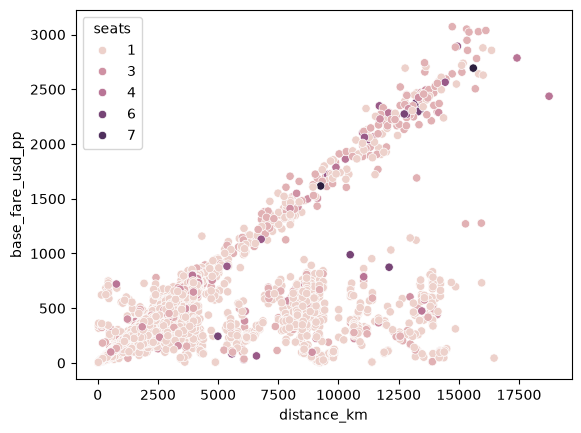

In [ ]:
sns.scatterplot(flights, y="base_fare_usd_pp", x="distance_km", hue="seats")

In [ ]:
flights

,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd,distance_km,base_fare_usd_pp,base_usd_per_km
0,204943-07ddf3a4d2a34e03befdbd07c78d9aab,YOW,new york,LGA,3,True,2023-03-06 07:00:00,2023-03-09 07:00:00,0,KLM Royal Dutch Airlines,40.640,-73.779,267.58,526.036985,89.193333,0.169557
1,229330-b73ffe29221b40a086cd0107f85eac2b,COS,san antonio,RND,1,True,2023-02-26 15:00:00,2023-03-02 15:00:00,0,United Airlines,29.529,-98.279,213.01,1187.884946,213.010000,0.179319
2,283325-dd763c2d6d334b3790266b500393438e,DAL,quebec,YQB,1,True,2023-03-05 14:00:00,2023-03-11 14:00:00,0,Air Canada,46.788,-71.398,453.27,2650.882368,453.270000,0.170988
3,347778-1bc6f3542683460480d91602d0a05a22,LSV,san diego,NZY,1,True,2023-06-26 11:00:00,2023-06-29 11:00:00,1,Ryanair,32.699,-117.215,77.49,441.165331,77.490000,0.175648
4,389434-cf10e38f0d464b81ace3f3be9f689833,LGA,hamilton,YHM,1,True,2023-04-06 07:00:00,2023-04-07 07:00:00,1,WestJet,43.173,-79.935,105.77,567.389136,105.770000,0.186415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13712,679066-34fe218a3ebf429795d788fe6d1b4319,MXF,el paso,ELP,1,True,2023-06-30 11:00:00,2023-07-02 11:00:00,1,Air France,31.849,-106.380,301.52,1883.509967,301.520000,0.160084
13713,698573-1ab935d1f3c146ffbbf6fdeeb2415e33,EWR,new york,LGA,1,True,2023-06-08 11:00:00,2023-06-19 11:00:00,0,JetBlue Airways,40.640,-73.779,6.53,26.667162,6.530000,0.244870
13714,767426-33cd5443192c434d96a21f558b068009,FYV,new york,JFK,3,True,2023-06-14 09:00:00,2023-06-16 09:00:00,0,Delta Air Lines,40.640,-73.779,990.19,1847.124018,330.063333,0.178690
13715,774666-b8e9ae456e874a5eaa038863565178fb,MSP,toronto,YTZ,1,True,2023-06-27 07:00:00,2023-06-29 07:00:00,1,Porter Airlines,43.862,-79.370,197.13,1108.518937,197.130000,0.177832


In [ ]:
flights["base_usd_per_km"].describe()

count    12721.000000
mean         0.171378
std          0.197305
min          0.000261
25%          0.166757
50%          0.176983
75%          0.185803
max         13.919308
Name: base_usd_per_km, dtype: float64

In [ ]:
df_worldmap = flights.groupby(["destination_airport_lat", "destination_airport_lon"])["trip_id"].count().reset_index()

In [ ]:
df_worldmap

,destination_airport_lat,destination_airport_lon,trip_id
0,-37.008,174.792,2
1,-34.559,-58.416,1
2,-33.965,18.602,2
3,-29.970,30.950,2
4,-25.986,28.140,2
...,...,...,...
120,53.630,9.988,2
121,53.667,-113.467,236
122,55.618,12.656,2
123,55.950,-3.373,3


In [ ]:
import plotly.express as px
import pandas as pd



# Create scatter map
fig = px.scatter_geo(
    df_worldmap,
    lat='destination_airport_lat',
    lon='destination_airport_lon',
    color= 'trip_id',
    width=1200,      # px
    height=800       # p
)

fig.show()

<Axes: xlabel='base_fare_usd', ylabel='Count'>

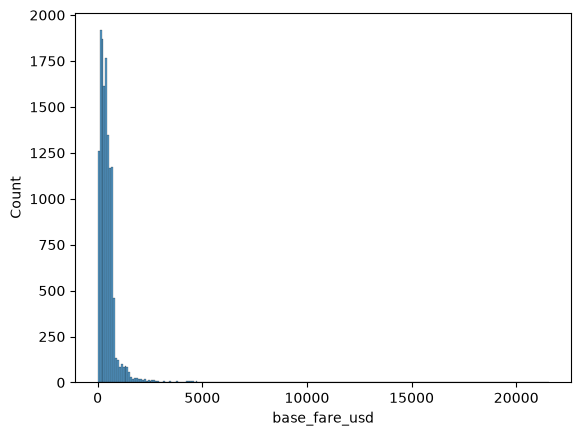

In [ ]:
sns.histplot(flights["base_fare_usd"])

<Axes: xlabel='base_fare_usd', ylabel='Count'>

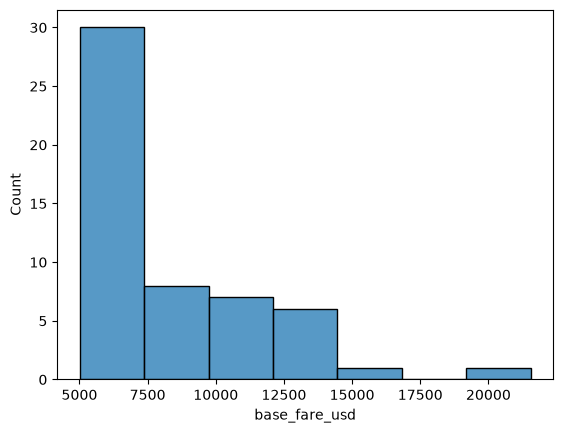

In [ ]:
sns.histplot(flights[flights["base_fare_usd"]>5000]["base_fare_usd"])


In [ ]:
flights

,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd,distance_km,base_fare_usd_pp,base_usd_per_km
0,204943-07ddf3a4d2a34e03befdbd07c78d9aab,YOW,new york,LGA,3,True,2023-03-06 07:00:00,2023-03-09 07:00:00,0,KLM Royal Dutch Airlines,40.640,-73.779,267.58,526.036985,89.193333,0.169557
1,229330-b73ffe29221b40a086cd0107f85eac2b,COS,san antonio,RND,1,True,2023-02-26 15:00:00,2023-03-02 15:00:00,0,United Airlines,29.529,-98.279,213.01,1187.884946,213.010000,0.179319
2,283325-dd763c2d6d334b3790266b500393438e,DAL,quebec,YQB,1,True,2023-03-05 14:00:00,2023-03-11 14:00:00,0,Air Canada,46.788,-71.398,453.27,2650.882368,453.270000,0.170988
3,347778-1bc6f3542683460480d91602d0a05a22,LSV,san diego,NZY,1,True,2023-06-26 11:00:00,2023-06-29 11:00:00,1,Ryanair,32.699,-117.215,77.49,441.165331,77.490000,0.175648
4,389434-cf10e38f0d464b81ace3f3be9f689833,LGA,hamilton,YHM,1,True,2023-04-06 07:00:00,2023-04-07 07:00:00,1,WestJet,43.173,-79.935,105.77,567.389136,105.770000,0.186415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13712,679066-34fe218a3ebf429795d788fe6d1b4319,MXF,el paso,ELP,1,True,2023-06-30 11:00:00,2023-07-02 11:00:00,1,Air France,31.849,-106.380,301.52,1883.509967,301.520000,0.160084
13713,698573-1ab935d1f3c146ffbbf6fdeeb2415e33,EWR,new york,LGA,1,True,2023-06-08 11:00:00,2023-06-19 11:00:00,0,JetBlue Airways,40.640,-73.779,6.53,26.667162,6.530000,0.244870
13714,767426-33cd5443192c434d96a21f558b068009,FYV,new york,JFK,3,True,2023-06-14 09:00:00,2023-06-16 09:00:00,0,Delta Air Lines,40.640,-73.779,990.19,1847.124018,330.063333,0.178690
13715,774666-b8e9ae456e874a5eaa038863565178fb,MSP,toronto,YTZ,1,True,2023-06-27 07:00:00,2023-06-29 07:00:00,1,Porter Airlines,43.862,-79.370,197.13,1108.518937,197.130000,0.177832


In [ ]:
flights["trip_airline"].value_counts()

trip_airline
Delta Air Lines       2098
American Airlines     2063
United Airlines       1844
Southwest Airlines    1099
Ryanair                916
                      ... 
Air Sahara               1
Metro Batavia            1
Czech Airlines           1
Air Serbia               1
Air Philippines          1
Name: count, Length: 175, dtype: int64

In [ ]:
flights

,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd,distance_km,base_fare_usd_pp,base_usd_per_km
0,204943-07ddf3a4d2a34e03befdbd07c78d9aab,YOW,new york,LGA,3,True,2023-03-06 07:00:00,2023-03-09 07:00:00,0,KLM Royal Dutch Airlines,40.640,-73.779,267.58,526.036985,89.193333,0.169557
1,229330-b73ffe29221b40a086cd0107f85eac2b,COS,san antonio,RND,1,True,2023-02-26 15:00:00,2023-03-02 15:00:00,0,United Airlines,29.529,-98.279,213.01,1187.884946,213.010000,0.179319
2,283325-dd763c2d6d334b3790266b500393438e,DAL,quebec,YQB,1,True,2023-03-05 14:00:00,2023-03-11 14:00:00,0,Air Canada,46.788,-71.398,453.27,2650.882368,453.270000,0.170988
3,347778-1bc6f3542683460480d91602d0a05a22,LSV,san diego,NZY,1,True,2023-06-26 11:00:00,2023-06-29 11:00:00,1,Ryanair,32.699,-117.215,77.49,441.165331,77.490000,0.175648
4,389434-cf10e38f0d464b81ace3f3be9f689833,LGA,hamilton,YHM,1,True,2023-04-06 07:00:00,2023-04-07 07:00:00,1,WestJet,43.173,-79.935,105.77,567.389136,105.770000,0.186415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13712,679066-34fe218a3ebf429795d788fe6d1b4319,MXF,el paso,ELP,1,True,2023-06-30 11:00:00,2023-07-02 11:00:00,1,Air France,31.849,-106.380,301.52,1883.509967,301.520000,0.160084
13713,698573-1ab935d1f3c146ffbbf6fdeeb2415e33,EWR,new york,LGA,1,True,2023-06-08 11:00:00,2023-06-19 11:00:00,0,JetBlue Airways,40.640,-73.779,6.53,26.667162,6.530000,0.244870
13714,767426-33cd5443192c434d96a21f558b068009,FYV,new york,JFK,3,True,2023-06-14 09:00:00,2023-06-16 09:00:00,0,Delta Air Lines,40.640,-73.779,990.19,1847.124018,330.063333,0.178690
13715,774666-b8e9ae456e874a5eaa038863565178fb,MSP,toronto,YTZ,1,True,2023-06-27 07:00:00,2023-06-29 07:00:00,1,Porter Airlines,43.862,-79.370,197.13,1108.518937,197.130000,0.177832


In [163]:
flights.to_csv("../data_preprocessed/flights_preprocessed.csv", index=False)

In [164]:
f = pd.read_csv("../data_preprocessed/flights_preprocessed.csv")
f

,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd,distance_km,base_fare_usd_pp,base_usd_pp_per_km
0,204943-07ddf3a4d2a34e03befdbd07c78d9aab,YOW,new york,LGA,3,True,2023-03-06 07:00:00,2023-03-09 07:00:00,0,KLM Royal Dutch Airlines,40.640,-73.779,267.58,526.036985,89.193333,0.169557
1,229330-b73ffe29221b40a086cd0107f85eac2b,COS,san antonio,RND,1,True,2023-02-26 15:00:00,2023-03-02 15:00:00,0,United Airlines,29.529,-98.279,213.01,1187.884946,213.010000,0.179319
2,283325-dd763c2d6d334b3790266b500393438e,DAL,quebec,YQB,1,True,2023-03-05 14:00:00,2023-03-11 14:00:00,0,Air Canada,46.788,-71.398,453.27,2650.882368,453.270000,0.170988
3,347778-1bc6f3542683460480d91602d0a05a22,LSV,san diego,NZY,1,True,2023-06-26 11:00:00,2023-06-29 11:00:00,1,Ryanair,32.699,-117.215,77.49,441.165331,77.490000,0.175648
4,389434-cf10e38f0d464b81ace3f3be9f689833,LGA,hamilton,YHM,1,True,2023-04-06 07:00:00,2023-04-07 07:00:00,1,WestJet,43.173,-79.935,105.77,567.389136,105.770000,0.186415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13712,679066-34fe218a3ebf429795d788fe6d1b4319,MXF,el paso,ELP,1,True,2023-06-30 11:00:00,2023-07-02 11:00:00,1,Air France,31.849,-106.380,301.52,1883.509967,301.520000,0.160084
13713,698573-1ab935d1f3c146ffbbf6fdeeb2415e33,EWR,new york,LGA,1,True,2023-06-08 11:00:00,2023-06-19 11:00:00,0,JetBlue Airways,40.640,-73.779,6.53,26.667162,6.530000,0.244870
13714,767426-33cd5443192c434d96a21f558b068009,FYV,new york,JFK,3,True,2023-06-14 09:00:00,2023-06-16 09:00:00,0,Delta Air Lines,40.640,-73.779,990.19,1847.124018,330.063333,0.178690
13715,774666-b8e9ae456e874a5eaa038863565178fb,MSP,toronto,YTZ,1,True,2023-06-27 07:00:00,2023-06-29 07:00:00,1,Porter Airlines,43.862,-79.370,197.13,1108.518937,197.130000,0.177832


# Session

In [37]:
sessions = pd.read_csv("../data/sessions.csv")

In [38]:
sessions

,session_id,user_id,trip_id,session_start,session_end,flight_discount,hotel_discount,flight_discount_amount,hotel_discount_amount,flight_booked,hotel_booked,page_clicks,cancellation
0,559164-e4d39929bc6040b1b58e2f774b807348,559164,559164-ae58e1fbf8db4f27846fb70c8308ee40,2023-04-02 19:56:00,2023-04-02 19:59:49,False,False,NaN,NaN,True,True,31,False
1,559469-2027a778257341c280db87d26ce9e4e3,559469,559469-aa0fd2b0ee2a403f82e3cf84388c2da3,2023-04-02 12:56:00,2023-04-02 12:57:39,False,False,NaN,NaN,True,False,13,False
2,561331-fb661b0fa33449a187f26b438658a6a5,561331,561331-6478dc007052490e87afee54982c434f,2023-04-02 18:08:00,2023-04-02 18:10:01,False,True,NaN,0.10,True,True,16,False
3,563052-7a1cec53282d404d95495a12bb0de14f,563052,NaN,2023-04-02 20:18:00,2023-04-02 20:19:18,False,True,NaN,0.15,False,False,11,False
4,565460-f25739901563474aa9f4dbad1cc295bf,565460,NaN,2023-04-02 17:09:00,2023-04-02 17:10:35,False,True,NaN,0.10,False,False,13,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49206,543716-c0a36a0263c24262a2ea76f07a8b995f,543716,543716-cefacd82315843a1a083e1bb070e1e11,2023-04-02 20:03:00,2023-04-02 20:05:35,False,False,NaN,NaN,True,True,21,False
49207,545318-3e9a87cf93164fe48f5a650b7dbd35cd,545318,NaN,2023-04-02 20:14:00,2023-04-02 20:16:42,False,False,NaN,NaN,False,False,22,False
49208,549235-32a0d455a8c04e458a621dd2999ea246,549235,NaN,2023-04-02 10:00:00,2023-04-02 10:00:58,False,False,NaN,NaN,False,False,8,False
49209,551600-250e4ebe55b842919c95ea1f995ae652,551600,NaN,2023-04-02 21:32:00,2023-04-02 21:33:15,True,False,0.2,NaN,False,False,10,False


## Nan values

In [39]:
sessions.info()

<class 'pandas.DataFrame'>
RangeIndex: 49211 entries, 0 to 49210
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   session_id              49211 non-null  str    
 1   user_id                 49211 non-null  int64  
 2   trip_id                 16702 non-null  str    
 3   session_start           49211 non-null  str    
 4   session_end             49211 non-null  str    
 5   flight_discount         49211 non-null  bool   
 6   hotel_discount          49211 non-null  bool   
 7   flight_discount_amount  8282 non-null   float64
 8   hotel_discount_amount   6205 non-null   float64
 9   flight_booked           49211 non-null  bool   
 10  hotel_booked            49211 non-null  bool   
 11  page_clicks             49211 non-null  int64  
 12  cancellation            49211 non-null  bool   
dtypes: bool(5), float64(2), int64(2), str(4)
memory usage: 3.2 MB


In [40]:
sessions[sessions["trip_id"].isnull()][["hotel_booked", "flight_booked"]].value_counts()

hotel_booked  flight_booked
False         False            32509
Name: count, dtype: int64

In [41]:
sessions[sessions["trip_id"].isnull()][["hotel_booked", "flight_booked"]].sum()

hotel_booked     0
flight_booked    0
dtype: int64

In [42]:
(~sessions[~sessions["trip_id"].isnull()][["hotel_discount_amount", "flight_discount_amount"]].isnull()).sum()

hotel_discount_amount     2229
flight_discount_amount    2402
dtype: int64

In [43]:
sessions[sessions["trip_id"].isnull()][["hotel_booked", "flight_booked"]].sum()

hotel_booked     0
flight_booked    0
dtype: int64

In [165]:
sessions.to_csv("../data_preprocessed/sessions_preprocessed.csv", index=False)

# Hotels

In [44]:
hotels = pd.read_csv("../data/hotels.csv")

In [45]:
hotels

,trip_id,hotel_name,nights,rooms,check_in_time,check_out_time,hotel_per_room_usd
0,118043-3148ad84821c481f81764ed8643adbbf,Fairmont - new york,8,1,2023-07-19 11:00:00,2023-07-27 11:00:00,177
1,204943-07ddf3a4d2a34e03befdbd07c78d9aab,Aman Resorts - new york,2,3,2023-03-06 09:40:43.05,2023-03-08 11:00:00,230
2,229009-406ee07a72a74789bb7b0f5bf0730fe0,Wyndham - edmonton,1,1,2023-05-27 14:18:53.46,2023-05-29 11:00:00,124
3,229330-b73ffe29221b40a086cd0107f85eac2b,Extended Stay - san antonio,1,1,2023-02-26 18:29:05.64,2023-02-28 11:00:00,229
4,283325-dd763c2d6d334b3790266b500393438e,Wyndham - quebec,4,1,2023-03-05 19:18:46.935,2023-03-10 11:00:00,527
...,...,...,...,...,...,...,...
14308,680735-4849063b26ae4997b20d156efc7dc99a,Conrad - winnipeg,1,2,2023-07-24 14:35:10.185,2023-07-26 11:00:00,202
14309,698573-1ab935d1f3c146ffbbf6fdeeb2415e33,Conrad - new york,10,1,2023-06-08 13:02:30.3,2023-06-19 11:00:00,306
14310,736075-004aa928ddc145cc8f24cfbc6088c8e4,InterContinental - san jose,2,1,2023-07-14 13:31:41.655,2023-07-17 11:00:00,147
14311,757930-4dbfad0ba9324d3d81f03e2e24cebfc8,Starwood - edmonton,5,1,2023-06-10 11:00:00,2023-06-15 11:00:00,207


- nights
- hotel_per_room what?
- name city

## Nights

In [46]:
hotels["check_in_time"] = pd.to_datetime(hotels["check_in_time"], format='mixed')
hotels["check_out_time"] = pd.to_datetime(hotels["check_out_time"], format='mixed')

In [47]:
hotels["check_out_time"] - hotels["check_in_time"]

0               8 days 00:00:00
1        2 days 01:19:16.950000
2        1 days 20:41:06.540000
3        1 days 16:30:54.360000
4        4 days 15:41:13.065000
                  ...          
14308    1 days 20:24:49.815000
14309   10 days 21:57:29.700000
14310    2 days 21:28:18.345000
14311           5 days 00:00:00
14312    1 days 20:16:50.250000
Length: 14313, dtype: timedelta64[us]

In [48]:
hotels["check_out_time"]

0       2023-07-27 11:00:00
1       2023-03-08 11:00:00
2       2023-05-29 11:00:00
3       2023-02-28 11:00:00
4       2023-03-10 11:00:00
                ...        
14308   2023-07-26 11:00:00
14309   2023-06-19 11:00:00
14310   2023-07-17 11:00:00
14311   2023-06-15 11:00:00
14312   2023-05-11 11:00:00
Name: check_out_time, Length: 14313, dtype: datetime64[us]

In [62]:
hotels["nights"] = (
    hotels["check_out_time"].dt.floor("D") 
    - hotels["check_in_time"].dt.floor("D")
).dt.days

In [63]:
hotels.loc[hotels["nights"]<1, "nights"] = 1

In [66]:
hotels[["hotel_name", "hotel_city"]] = hotels["hotel_name"].str.split(" - ", n=1, expand=True)

In [166]:
hotels.to_csv("../data_preprocessed/hotels_preprocessed.csv", index=False)